<a href="https://colab.research.google.com/github/Sunidhipatilcodes/THE-ML-ACTIVITY-/blob/main/Activity2_House_Price_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Activity 2: Simple House Price Prediction (Linear Regression)


## Step 1: Select and understand a dataset
- **Dataset:** California Housing (1990 US Census, one row per census block group)
- **Source:** Pace, R. K. and Barry, R. (1997), *Sparse Spatial Autoregressions*, Statistics & Probability Letters. Loaded with `sklearn.datasets.fetch_california_housing` (https://scikit-learn.org/stable/datasets/real_world.html#california-housing-dataset).
- **Target (y):** `MedHouseVal` – median house value, in units of **$100,000** (continuous, numerical).
- **Input feature (X):** `MedInc` – median household income in the block group, in units of **$10,000**.
- **Why income?** Areas where households earn more can usually afford more expensive houses, so income should be related to house value.

In [16]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

LOCAL = "housing.csv"   # optional fallback with the same column names

def load_data():
    try:
        from sklearn.datasets import fetch_california_housing
        return fetch_california_housing(as_frame=True).frame, "sklearn (fetch_california_housing)"
    except Exception as e:
        print("sklearn download failed:", e)
        if os.path.exists(LOCAL):
            return pd.read_csv(LOCAL), "local file"
        raise

df_raw, loaded_from = load_data()
print("Loaded from:", loaded_from)
print(df_raw.shape)

Loaded from: sklearn (fetch_california_housing)
(20640, 9)


In [17]:
print("Target is numeric:", pd.api.types.is_numeric_dtype(df_raw["MedHouseVal"]))
print("Unique target values:", df_raw["MedHouseVal"].nunique(), "(many distinct values -> continuous)")

Target is numeric: True
Unique target values: 3842 (many distinct values -> continuous)


## Step 2: Load and inspect the data

In [18]:
display(df_raw.head())
print("Rows:", df_raw.shape[0], "| Columns:", df_raw.shape[1])
print("\nColumn names:", list(df_raw.columns))
print("\nData types:"); print(df_raw.dtypes)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


Rows: 20640 | Columns: 9

Column names: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']

Data types:
MedInc         float64
HouseAge       float64
AveRooms       float64
AveBedrms      float64
Population     float64
AveOccup       float64
Latitude       float64
Longitude      float64
MedHouseVal    float64
dtype: object


In [19]:
display(df_raw.describe().T)
print("Missing values per column:"); print(df_raw.isnull().sum())
print("\nDuplicate rows:", int(df_raw.duplicated().sum()))

,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
MedHouseVal,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


Missing values per column:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Duplicate rows: 0


### Handling invalid values
The target `MedHouseVal` is **capped at 5.0** ($500,000) in this dataset, so every house worth more than that is recorded as exactly 5.0. These values are not true prices (they are *censored*) and they pull a straight-line fit downward. They are checked below and removed, with the reason documented. The same check is done for `MedInc`, which is also capped at 15.

In [20]:
cap_target = df_raw["MedHouseVal"].max()
n_cap = int((df_raw["MedHouseVal"] == cap_target).sum())
print(f"Rows with target at the cap ({cap_target}):", n_cap)

df = df_raw.drop_duplicates()
df = df[df["MedHouseVal"] < cap_target].copy()
print("Rows after removing capped targets:", len(df), "(removed", len(df_raw) - len(df), "rows)")

Rows with target at the cap (5.00001): 965
Rows after removing capped targets: 19675 (removed 965 rows)


## Step 3: Select input feature and target
- **X = `MedInc`** (median income). The dataset has no square-footage column, and income is its strongest single predictor.
- **y = `MedHouseVal`** (median house value, $100,000 units).
- No ID column is used as a feature.

In [21]:
X = df[["MedInc"]]
y = df["MedHouseVal"]
print("X shape:", X.shape, "| y shape:", y.shape)
print("Correlation between MedInc and MedHouseVal:", round(X["MedInc"].corr(y), 3))

X shape: (19675, 1) | y shape: (19675,)
Correlation between MedInc and MedHouseVal: 0.643


## Step 4: Visualise the relationship

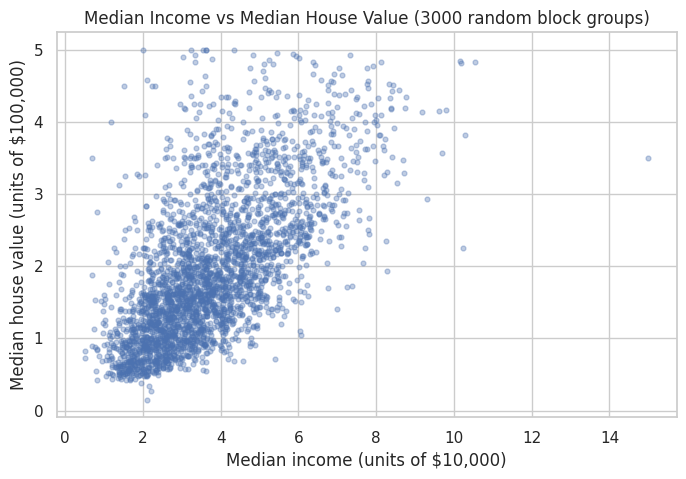

In [22]:
plt.figure(figsize=(8, 5))
sample = df.sample(3000, random_state=42)
plt.scatter(sample["MedInc"], sample["MedHouseVal"], alpha=0.35, s=12)
plt.title("Median Income vs Median House Value (3000 random block groups)")
plt.xlabel("Median income (units of $10,000)")
plt.ylabel("Median house value (units of $100,000)")
plt.show()

**Interpretation :** the points trend upward, so the relationship is **positive**, but there is a lot of spread (moderate strength) and it flattens at high incomes. A visible relationship does **not** prove causation: higher income does not by itself *cause* higher prices; location, house age and other factors can influence both.

## Step 5: Split the data (80:20)
Training data is used to learn the model's parameters (slope and intercept). Test data is held back and used only to measure performance on unseen observations.

In [23]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Training observations:", len(X_train))
print("Testing observations :", len(X_test))

Training observations: 15740
Testing observations : 3935


## Step 6: Train Linear Regression

In [24]:
model = LinearRegression()
model.fit(X_train, y_train)

slope = model.coef_[0]
intercept = model.intercept_
print("Intercept:", round(intercept, 4))
print("Coefficient (slope) for MedInc:", round(slope, 4))
print(f"\nEquation: MedHouseVal = {intercept:.4f} + {slope:.4f} x MedInc")

Intercept: 0.4622
Coefficient (slope) for MedInc: 0.3979

Equation: MedHouseVal = 0.4622 + 0.3979 x MedInc


In [25]:
print(f"Slope meaning    : each extra 1 unit of MedInc ($10,000) changes the predicted house value by "
      f"{slope:.3f} units (${slope*100000:,.0f}).")
print(f"Intercept meaning: predicted value when MedInc = 0 is {intercept:.3f} units (${intercept*100000:,.0f}); "
      "this is a mathematical starting point, not a realistic case.")

Slope meaning    : each extra 1 unit of MedInc ($10,000) changes the predicted house value by 0.398 units ($39,789).
Intercept meaning: predicted value when MedInc = 0 is 0.462 units ($46,224); this is a mathematical starting point, not a realistic case.


## Step 7: Generate predictions (test set)

In [26]:
y_pred = model.predict(X_test)

comparison = pd.DataFrame({
    "MedInc": X_test["MedInc"].values,
    "Actual": y_test.values,
    "Predicted": y_pred,
})
comparison["Error (Actual - Predicted)"] = comparison["Actual"] - comparison["Predicted"]
display(comparison.head(10).round(3))

,MedInc,Actual,Predicted,Error (Actual - Predicted)
0,1.836,1.042,1.193,-0.151
1,4.211,1.712,2.138,-0.426
2,4.048,0.973,2.073,-1.100
3,3.538,1.027,1.870,-0.843
4,2.200,1.165,1.338,-0.173
5,1.133,1.048,0.913,0.135
6,2.543,0.673,1.474,-0.801
7,1.571,0.430,1.087,-0.657
8,2.982,1.620,1.649,-0.029
9,5.307,1.327,2.574,-1.247


**Observation :** some predictions are close to the actual values while others are far off; the model uses only income, so it cannot account for location, house age or size.

## Step 8: Evaluate the model
- **MAE** – average absolute error, in the target's units.
- **MSE** – average of squared errors; punishes large errors more.
- **RMSE** – square root of MSE, back in the target's units.
- **R²** – how much better the model is than always predicting the mean; it can be negative on test data if the model is worse than that baseline.

In [27]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"MAE  : {mae:.4f}  (about ${mae*100000:,.0f})")
print(f"MSE  : {mse:.4f}")
print(f"RMSE : {rmse:.4f}  (about ${rmse*100000:,.0f})")
print(f"R2   : {r2:.4f}  -> income explains about {r2*100:.1f}% of the variation in house value")
print(f"\nFor scale: mean actual test value = {y_test.mean():.3f} (${y_test.mean()*100000:,.0f})")

MAE  : 0.5791  (about $57,911)
MSE  : 0.5785
RMSE : 0.7606  (about $76,059)
R2   : 0.4198  -> income explains about 42.0% of the variation in house value

For scale: mean actual test value = 1.936 ($193,625)


**Interpretation :** compare the MAE/RMSE with the average house value printed above to judge how large the typical error is. An R² well below 1 means a single feature leaves much of the price variation unexplained, which is expected.

## Step 9: Actual vs predicted

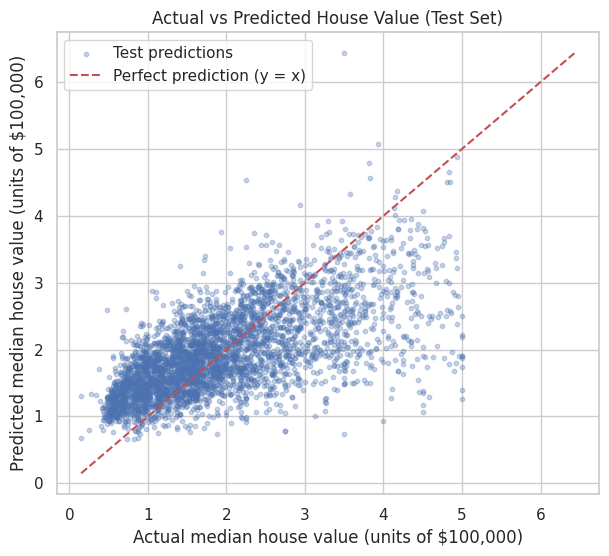

In [28]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.3, s=10, label="Test predictions")
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(lims, lims, "r--", label="Perfect prediction (y = x)")
plt.title("Actual vs Predicted House Value (Test Set)")
plt.xlabel("Actual median house value (units of $100,000)")
plt.ylabel("Predicted median house value (units of $100,000)")
plt.legend()
plt.show()

**Interpretation :** points close to the red dashed line are accurate predictions. A wide cloud around the line, and under-prediction of the most expensive blocks, show that income alone is not enough to explain price.

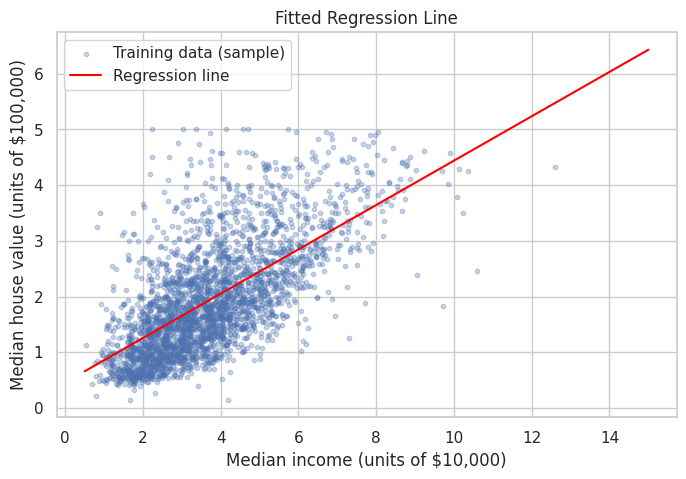

In [29]:
# Also show the fitted line on the training data
plt.figure(figsize=(8, 5))
plt.scatter(X_train["MedInc"].sample(3000, random_state=1), y_train.loc[X_train["MedInc"].sample(3000, random_state=1).index],
            alpha=0.3, s=10, label="Training data (sample)")
xs = pd.DataFrame({"MedInc": np.linspace(X["MedInc"].min(), X["MedInc"].max(), 100)})
plt.plot(xs["MedInc"], model.predict(xs), color="red", label="Regression line")
plt.title("Fitted Regression Line")
plt.xlabel("Median income (units of $10,000)")
plt.ylabel("Median house value (units of $100,000)")
plt.legend(); plt.show()

## Step 10: Predict a new example and conclude

In [30]:
new_income = 4.0   # = $40,000, inside the training range
print("Training range of MedInc:", round(X_train["MedInc"].min(), 2), "to", round(X_train["MedInc"].max(), 2))

new_pred = model.predict(pd.DataFrame({"MedInc": [new_income]}))[0]
print(f"For MedInc = {new_income} (${new_income*10000:,.0f}) the predicted median house value is "
      f"{new_pred:.3f} units = ${new_pred*100000:,.0f}")

Training range of MedInc: 0.5 to 15.0
For MedInc = 4.0 ($40,000) the predicted median house value is 2.054 units = $205,381


## Conclusion
- **Dataset:** California Housing, with capped target values removed.
- **Feature / target:** `MedInc` → `MedHouseVal`.
- **Model:** simple Linear Regression, 80:20 split, `random_state=42`.
- **Results:** see the equation and the MAE, MSE, RMSE and R² printed above.
- **Limitations:** only one feature is used; house prices also depend on location, house age, number of rooms, population and more. The data is from 1990 and describes block groups, not individual houses. Removing capped values means the model is not meant for very expensive areas. A multi-feature model would likely perform better.

In [31]:
df_raw.to_csv("california_housing.csv", index=False)
print("saved", df_raw.shape)

saved (20640, 9)
